In [ ]:
import comparison_utils
import numpy as np
from tqdm import tqdm
import matplotlib.pyplot as plt

class_label = 0

ps_big_matrix = np.load("../mini_ps/8k_ps_dist_matrix.npy")

ps_matrix = ps_big_matrix[
    class_label * 1000 : (class_label + 1) * 1000,
    class_label * 1000 : (class_label + 1) * 1000,
]
w2_matrix = np.load(f"../mini_w2/block_{class_label}_{class_label}.npy")


100%|██████████| 200/200 [00:18<00:00, 10.66it/s]


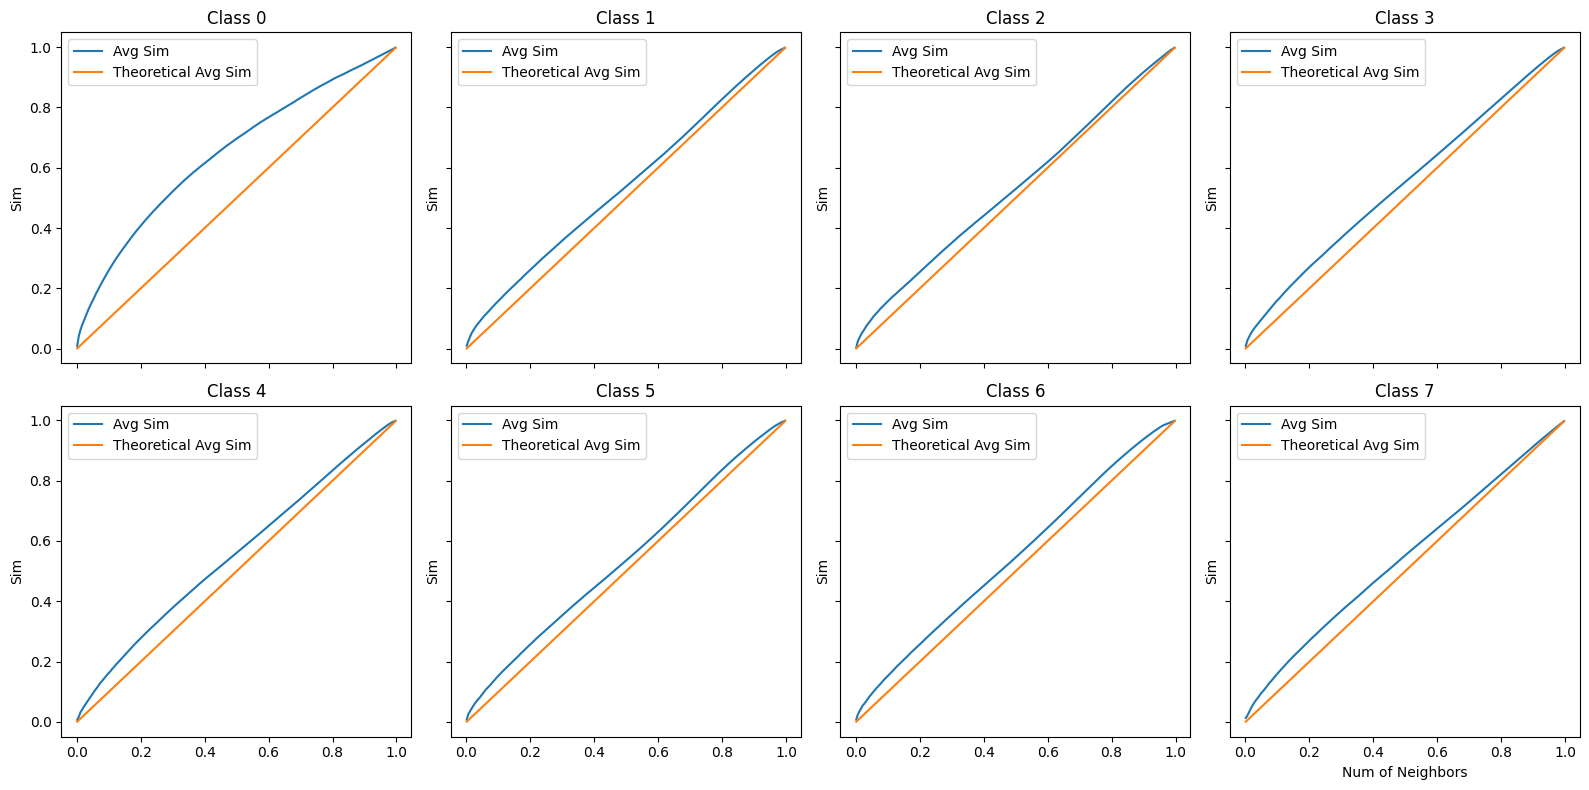

In [2]:
n_neighbors = np.arange(1, 999, 5)
length = 1000
theoretical_avg_sim = n_neighbors / (length - 1)
neighbor_percentage = np.arange(1 / 999, 1, 5 / 999)

class_labels = np.arange(8)

n_plots = len(class_labels)
ncols = 4
nrows = int(np.ceil(n_plots / ncols))
fig, axes = plt.subplots(
    nrows, ncols, figsize=(4 * ncols, 4 * nrows), sharex=True, sharey=True
)
axes = axes.flatten()

avg_sims = np.zeros((n_plots, n_neighbors.size))

for ax, class_label in zip(axes, class_labels):
    ps = np.copy(
        ps_big_matrix[
            class_label * 1000 : (class_label + 1) * 1000,
            class_label * 1000 : (class_label + 1) * 1000,
        ]
    )
    w2 = np.load(f"../mini_w2/block_{class_label}_{class_label}.npy")

    for i, n in tqdm(enumerate(n_neighbors), total=n_neighbors.size):
        avg_sims[class_label][i] = comparison_utils.average_strict_jaccard(w2, ps, n)

    ax.plot(neighbor_percentage, avg_sims[class_label], label="Avg Sim")
    ax.plot(neighbor_percentage, theoretical_avg_sim, label="Theoretical Avg Sim")
    ax.set_title(f"Class {class_label}")
    ax.set_ylabel("Sim")
    ax.legend()

# common X-axis label on bottom
axes[-1].set_xlabel("Num of Neighbors")

plt.tight_layout()
plt.show()

In [3]:
from scipy.integrate import simpson

aucs_scipy = np.zeros(len(class_labels))
for i in range(len(class_labels)):
    aucs_scipy[i] = simpson(y=avg_sims[i], x=neighbor_percentage)

print(np.round(aucs_scipy, 3))

aucs_numpy = np.zeros(len(class_labels))
for i in range(len(class_labels)):
    aucs_numpy[i] = np.trapz(y=avg_sims[i], x=neighbor_percentage)
print(np.round(aucs_numpy, 3))

[0.644 0.536 0.529 0.543 0.549 0.536 0.543 0.54 ]
[0.644 0.536 0.529 0.543 0.549 0.536 0.543 0.54 ]
